## **Лабораторная работа 4. Уравнение теплопроводности**

Найти температуру в стенке «пенопласт — кирпич — пенопласт»:
$\rho c T_t=(\lambda T_x)_x$.
Слева 20 °C, справа −50 °C, внутри в начальный момент −50 °C.
На стыках непрерывны температура и тепловой поток.

Учебные толщины и свойства слоёв согласованы в чате:
d = 5/25/5 см, λ = 0.04/0.7/0.04, ρ = 30/1800/30, c = 1400/840/1400.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

Path('results').mkdir(exist_ok=True)
d = np.array([0.05, 0.25, 0.05])
lam = np.array([0.04, 0.7, 0.04])
rho = np.array([30., 1800., 30.])
c = np.array([1400., 840., 1400.])
T_left, T_right, T0 = 20., -50., -50.
N = 20                         # Отрезков в каждом слое
T = 7 * 24 * 3600              # Время расчёта, с
M = 1008
tau = T / M

### Сетка и начальные условия

В каждом слое 20 отрезков. Границы материалов совпадают с узлами.
G = λ/h — проводимость отрезка, C — теплоёмкость узлового контрольного объёма.

In [2]:
borders = np.r_[0, np.cumsum(d)]
x = np.r_[np.linspace(borders[0], borders[1], N+1),
          np.linspace(borders[1], borders[2], N+1)[1:],
          np.linspace(borders[2], borders[3], N+1)[1:]]
h = np.diff(x)
G = np.repeat(lam, N) / h
capacity = np.repeat(rho*c, N) * h
C = 0.5 * (capacity[:-1] + capacity[1:])
t = np.linspace(0, T, M+1)
u = np.full((M+1, 3*N+1), T0)
u[:,0] = T_left
u[:,-1] = T_right

### Метод прогонки

In [3]:
def progonka(a, b, c, d):
    n = len(b)
    alpha, beta = np.zeros(n-1), np.zeros(n)
    alpha[0] = c[0] / b[0]
    beta[0] = d[0] / b[0]
    for i in range(1, n):
        z = b[i] - a[i-1] * alpha[i-1]
        if i < n-1:
            alpha[i] = c[i] / z
        beta[i] = (d[i] - a[i-1] * beta[i-1]) / z
    y = np.zeros(n)
    y[-1] = beta[-1]
    for i in range(n-2, -1, -1):
        y[i] = beta[i] - alpha[i] * y[i+1]
    return y

### Неявная разностная схема

$C_i(T_i^{j+1}-T_i^j)=\tau[G_{i-1/2}(T_{i-1}^{j+1}-T_i^{j+1})+
G_{i+1/2}(T_{i+1}^{j+1}-T_i^{j+1})]$.

Отдельно учитываем λ и ρc, чтобы сохранить тепловой баланс на стыках слоёв.

In [4]:
a = -tau * G[1:-1]
b = C + tau * (G[:-1] + G[1:])
q1 = np.zeros(M)
q2 = np.zeros(M)
balance = np.zeros(M)
for j in range(M):
    rhs = C * u[j,1:-1]
    rhs[0] += tau * G[0] * T_left
    rhs[-1] += tau * G[-1] * T_right
    u[j+1,1:-1] = progonka(a, b, a, rhs)
    q1[j] = G[0] * (u[j+1,0] - u[j+1,1])
    q2[j] = G[-1] * (u[j+1,-2] - u[j+1,-1])
    dE = np.sum(C * (u[j+1,1:-1] - u[j,1:-1]))
    heat = tau * (q1[j] - q2[j])
    balance[j] = abs(dE - heat) / max(abs(dE), abs(heat), 1.)

### Стационарное решение и проверка

$q_\infty=(T_\text{left}-T_\text{right})/\sum d_i/\lambda_i$.
Разность входящего и выходящего потоков равна накоплению тепла.

In [5]:
q_stationary = (T_left - T_right) / np.sum(d / lam)
resistance = np.r_[0, np.cumsum(1 / G)]
u_stationary = T_left - q_stationary * resistance
rhs = np.zeros(3*N-1)
rhs[0] = G[0] * T_left
rhs[-1] = G[-1] * T_right
u_check = progonka(-G[1:-1], G[:-1]+G[1:], -G[1:-1], rhs)
print('Стационарный поток:', q_stationary, 'Вт/м²')
print('Температуры на стыках:', u_stationary[N], u_stationary[2*N])
print('Ошибка стационарного решения:', max(abs(u_check-u_stationary[1:-1])))
print('Максимальная ошибка баланса:', balance.max())
print('Пределы температуры:', u.min(), u.max())
assert balance.max() < 1e-7
assert max(abs(u_check-u_stationary[1:-1])) < 1e-8
assert u.min() >= T_right-1e-8 and u.max() <= T_left+1e-8
np.savez('results/heat.npz', x=x, t=t, u=u, q1=q1, q2=q2,
         balance=balance, stationary=u_stationary)
np.savetxt('results/temperature.csv', np.column_stack([x, u[0], u[6], u[36], u[144], u[-1], u_stationary]),
           delimiter=',', header='x,t0,t1h,t6h,t24h,t168h,stationary', comments='')
np.savetxt('results/flux.csv', np.column_stack([t[1:],q1,q2]),
           delimiter=',', header='time_s,q_left,q_right', comments='')

Стационарный поток: 24.5 Вт/м²
Температуры на стыках: -10.624999999999993 -19.374999999999964
Ошибка стационарного решения: 1.9539925233402755e-13
Максимальная ошибка баланса: 4.2539054200535555e-13
Пределы температуры: -50.0 20.0


### Визуализация решения

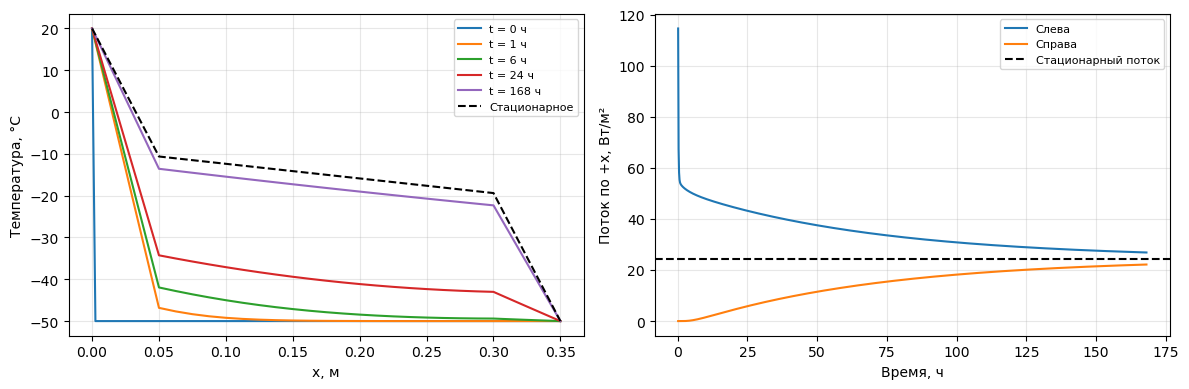

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for j in [0, 6, 36, 144, M]:
    ax[0].plot(x, u[j], label=f't = {t[j]/3600:g} ч')
ax[0].plot(x, u_stationary, 'k--', label='Стационарное')
ax[0].set(xlabel='x, м', ylabel='Температура, °C')
ax[1].plot(t[1:]/3600, q1, label='Слева')
ax[1].plot(t[1:]/3600, q2, label='Справа')
ax[1].axhline(q_stationary, color='black', linestyle='--', label='Стационарный поток')
ax[1].set(xlabel='Время, ч', ylabel='Поток по +x, Вт/м²')
for a in ax:
    a.legend(fontsize=8)
    a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('results/heat.png', dpi=150)
plt.show()

### Вывод

Стенка постепенно прогревается слева. Температура непрерывна, её наклон
меняется на стыках из-за разных λ. В стационарном состоянии поток равен
24.5 Вт/м², температуры на стыках −10.625 и −19.375 °C.
За 7 суток решение приближается к стационарному, но ещё не совпадает с ним.